In [1]:
import sys
from pathlib import Path

# O notebook roda a partir de notebooks/, entao a raiz do projeto
# precisa entrar no sys.path para o import de src funcionar.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing.montagem import carregar_base
from src.visualization.graficos import salvar_figura

df = carregar_base()
print(df.shape)
df.head()

(1851828, 19)


,id_aluno,id_escola,id_municipio,sigla_uf,rede,serie,caderno,peso_aluno,alfabetizado,escola_alunos_2024,muni_taxa_municipal_2023,muni_media_pt_municipal_2023,muni_participacao_municipal_2023,muni_taxa_estadual_2023,muni_media_pt_estadual_2023,muni_participacao_estadual_2023,muni_taxa_publica_2023,muni_media_pt_publica_2023,muni_participacao_publica_2023
0,26012022,60011955,2608404,PE,Municipal,2,1,1.0,1,57,53.46,737.4392,91.93,NaN,NaN,NaN,53.46,737.4392,NaN
1,26012905,60012706,2612307,PE,Municipal,2,1,1.0,1,14,58.09,756.0296,96.10,NaN,NaN,NaN,58.09,756.0296,NaN
2,29157454,60015166,2922102,BA,Municipal,2,1,1.0,0,23,26.61,711.3384,91.76,NaN,NaN,NaN,26.61,711.3384,NaN
3,31139995,60021428,3130101,MG,Municipal,2,1,1.0,1,21,51.87,743.6566,83.95,NaN,NaN,NaN,51.87,743.6566,NaN
4,51005072,60040461,5102504,MT,Municipal,2,1,1.0,0,73,47.53,739.6200,87.98,NaN,NaN,NaN,47.53,739.6200,NaN


In [2]:
for col in ["serie", "caderno", "rede"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).to_string())

print("\npeso_aluno:")
print(df["peso_aluno"].describe().to_string())
print(f"\nproporcao de pesos iguais a 1: {(df['peso_aluno'] == 1).mean():.2%}")


serie:
serie
2    1851828

caderno:
caderno
1     97138
3     93366
5     93351
2     93301
4     93242
7     93064
6     93049
15    86462
8     86290
20    85437
10    85391
9     85313
12    85278
13    85242
16    85207
11    85200
17    85194
21    85160
18    85106
19    85054
14    84971
43       12

rede:
rede
Municipal    1610754
Estadual      241074

peso_aluno:
count    1.851828e+06
mean     1.138956e+00
std      2.056983e-01
min      1.000000e+00
25%      1.030000e+00
50%      1.090000e+00
75%      1.190000e+00
max      2.983000e+01

proporcao de pesos iguais a 1: 23.99%


In [3]:
por_caderno = df.groupby("caderno")["alfabetizado"].mean()
print("Taxa de alfabetizacao por caderno:")
print(f"  minima: {por_caderno.min():.2%}  (caderno {por_caderno.idxmin()})")
print(f"  maxima: {por_caderno.max():.2%}  (caderno {por_caderno.idxmax()})")
print(f"  amplitude: {(por_caderno.max() - por_caderno.min()) * 100:.1f} pp")

print("\nTaxa de alfabetizacao por rede:")
print(df.groupby("rede")["alfabetizado"].agg(["mean", "size"]).to_string())

Taxa de alfabetizacao por caderno:
  minima: 50.00%  (caderno 43)
  maxima: 60.46%  (caderno 12)
  amplitude: 10.5 pp

Taxa de alfabetizacao por rede:
               mean     size
rede                        
Estadual   0.625368   241074
Municipal  0.593724  1610754


In [4]:
tabela_caderno = (
    df.groupby("caderno")["alfabetizado"]
    .agg(taxa="mean", alunos="size")
    .sort_values("alunos")
)
tabela_caderno["taxa"] = (tabela_caderno["taxa"] * 100).round(1)
print(tabela_caderno.to_string())

         taxa  alunos
caderno              
43       50.0      12
14       60.2   84971
19       59.7   85054
18       58.7   85106
21       59.9   85160
17       59.2   85194
11       59.8   85200
16       59.7   85207
13       60.4   85242
12       60.5   85278
9        59.7   85313
10       60.3   85391
20       59.1   85437
8        60.4   86290
15       59.1   86462
6        60.1   93049
7        60.0   93064
4        59.9   93242
2        59.3   93301
5        60.2   93351
3        59.4   93366
1        59.6   97138


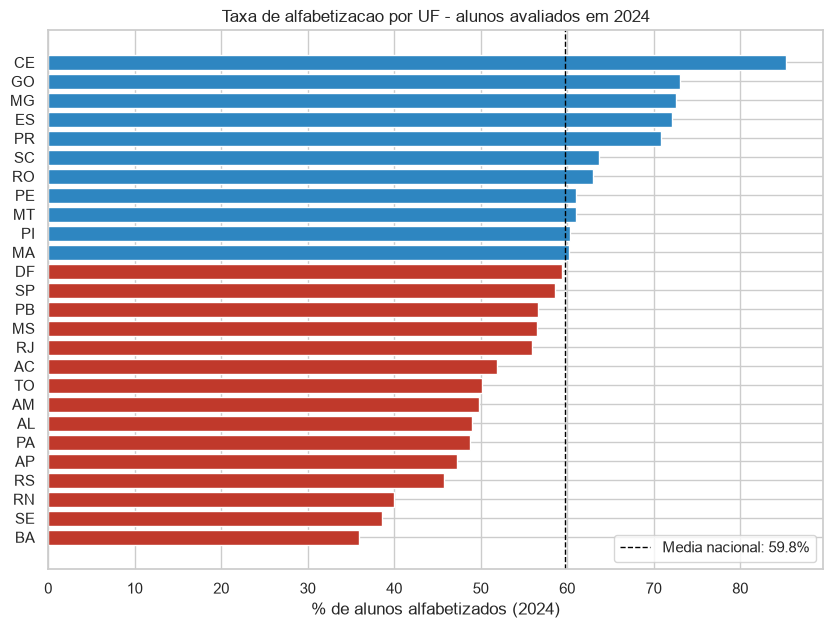

[OK] figura salva em images/eda_01_alfabetizacao_por_uf.png
Amplitude entre UFs: 49.4 pp


In [5]:
por_uf = df.groupby("sigla_uf")["alfabetizado"].mean().sort_values() * 100
media_nacional = df["alfabetizado"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 7))
cores = ["#c0392b" if v < media_nacional else "#2e86c1" for v in por_uf]
ax.barh(por_uf.index, por_uf.values, color=cores)
ax.axvline(media_nacional, color="black", linestyle="--", linewidth=1,
           label=f"Media nacional: {media_nacional:.1f}%")
ax.set_xlabel("% de alunos alfabetizados (2024)")
ax.set_title("Taxa de alfabetizacao por UF - alunos avaliados em 2024")
ax.legend(loc="lower right")
plt.show()

salvar_figura(fig, "eda_01_alfabetizacao_por_uf")
print(f"Amplitude entre UFs: {por_uf.max() - por_uf.min():.1f} pp")

In [7]:
nulos_uf = (
    df.groupby("sigla_uf")
    .agg(
        pct_escola_nova=("escola_nova", "mean"),
        pct_sem_muni=("muni_taxa_publica_2023", lambda s: s.isna().mean()),
        alunos=("alfabetizado", "size"),
    )
    .sort_values("pct_escola_nova", ascending=False)
)
nulos_uf[["pct_escola_nova", "pct_sem_muni"]] = (nulos_uf[["pct_escola_nova", "pct_sem_muni"]] * 100).round(1)
print(nulos_uf.to_string())

          pct_escola_nova  pct_sem_muni  alunos
sigla_uf                                       
SP                   90.6          42.2  395444
PR                   17.4           0.0  119806
AM                    0.0           0.0   46628
AP                    0.0           0.0   11214
BA                    0.0           0.0  104069
CE                    0.0           0.0   88158
DF                    0.0         100.0   22111
ES                    0.0           0.0   42751
AC                    0.0         100.0   10234
AL                    0.0           0.0   31575
MA                    0.0           0.0   62974
GO                    0.0           0.0   70799
MT                    0.0           0.0   45083
MG                    0.0           0.1  180771
PA                    0.0           0.0   83193
PB                    0.0           0.0   31004
PE                    0.0           0.0   75953
MS                    0.0           0.0   37212
PI                    0.0           0.0 

In [10]:
from src.preprocessing.extracao import consultar

teste_id = consultar("""
    WITH e AS (
        SELECT DISTINCT
            CAST(ano AS varchar) AS ano,
            CAST(id_escola AS varchar) AS id_escola,
            CAST(id_municipio AS varchar) AS id_municipio
        FROM silver_alunos
    )
    SELECT
        COUNT(*) AS escolas_nos_dois_anos,
        SUM(CASE WHEN a.id_municipio = b.id_municipio THEN 1 ELSE 0 END) AS mesmo_municipio,
        SUM(CASE WHEN SUBSTR(a.id_municipio, 1, 2) = SUBSTR(b.id_municipio, 1, 2) THEN 1 ELSE 0 END) AS mesma_uf
    FROM e a
    JOIN e b
      ON a.id_escola = b.id_escola
     AND a.ano = '2023'
     AND b.ano = '2024'
""")
print(teste_id.to_string(index=False))

 escolas_nos_dois_anos  mesmo_municipio  mesma_uf
                 36462              865     29424


Nulos na nova feature: 1.9%


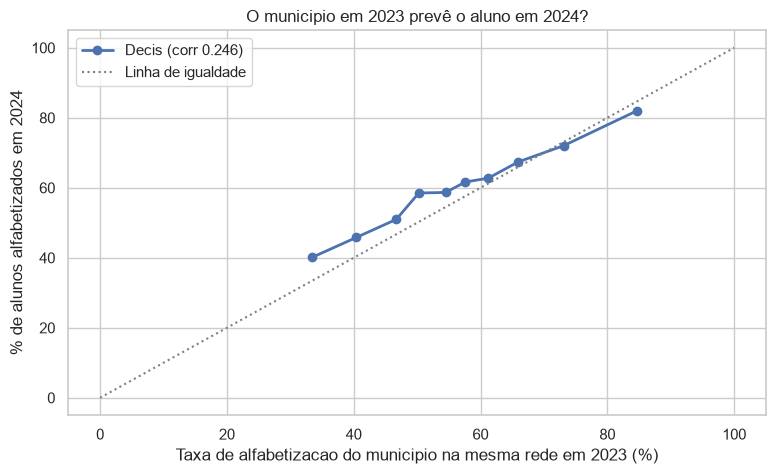

[OK] figura salva em images/eda_04_municipio_2023_vs_aluno_2024.png
muni_taxa_mesma_rede_2023
(3.4090000000000003, 37.87]    40.1
(37.87, 43.33]                 45.8
(43.33, 48.75]                 51.0
(48.75, 52.06]                 58.5
(52.06, 56.19]                 58.7
(56.19, 58.92]                 61.7
(58.92, 63.7]                  62.7
(63.7, 69.15]                  67.4
(69.15, 77.48]                 72.0
(77.48, 100.0]                 82.0


In [2]:
df["muni_taxa_mesma_rede_2023"] = (
    df["muni_taxa_municipal_2023"].where(df["rede"] == "Municipal",
                                         df["muni_taxa_estadual_2023"])
    .fillna(df["muni_taxa_publica_2023"])
)
print(f"Nulos na nova feature: {df['muni_taxa_mesma_rede_2023'].isna().mean():.1%}")

faixas = pd.qcut(df["muni_taxa_mesma_rede_2023"], q=10, duplicates="drop")
x = df.groupby(faixas, observed=True)["muni_taxa_mesma_rede_2023"].median()
y = df.groupby(faixas, observed=True)["alfabetizado"].mean() * 100
corr = df["muni_taxa_mesma_rede_2023"].corr(df["alfabetizado"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x.values, y.values, marker="o", linewidth=2, label=f"Decis (corr {corr:.3f})")
ax.plot([0, 100], [0, 100], color="gray", linestyle=":", label="Linha de igualdade")
ax.set_xlabel("Taxa de alfabetizacao do municipio na mesma rede em 2023 (%)")
ax.set_ylabel("% de alunos alfabetizados em 2024")
ax.set_title("O municipio em 2023 prevê o aluno em 2024?")
ax.legend()
plt.show()

salvar_figura(fig, "eda_04_municipio_2023_vs_aluno_2024")
print(y.round(1).to_string())

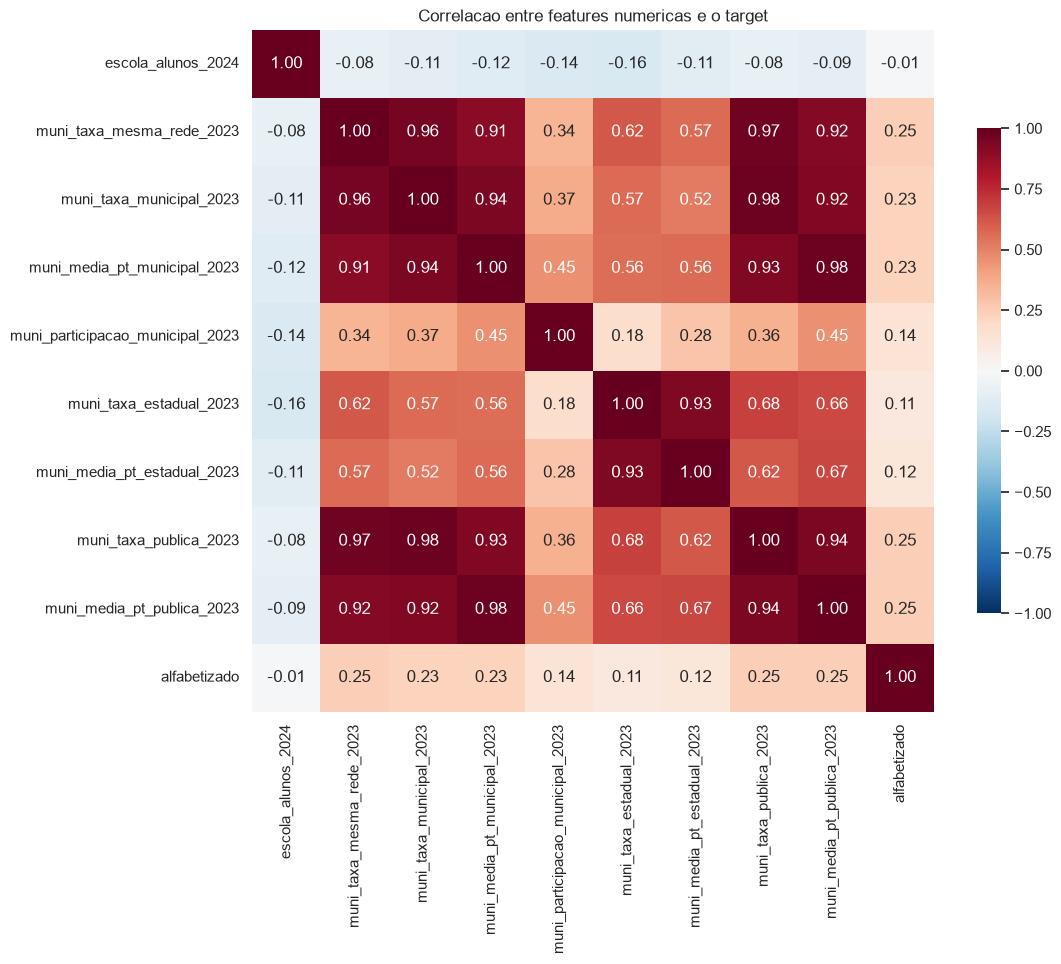

[OK] figura salva em images/eda_05_correlacao_features.png
Correlacao com o target (ordenada):
muni_media_pt_publica_2023          0.248
muni_taxa_publica_2023              0.248
muni_taxa_mesma_rede_2023           0.246
muni_media_pt_municipal_2023        0.232
muni_taxa_municipal_2023            0.232
muni_participacao_municipal_2023    0.140
muni_media_pt_estadual_2023         0.119
muni_taxa_estadual_2023             0.105
escola_alunos_2024                 -0.011


In [3]:
features_num = [
    "escola_alunos_2024",
    "muni_taxa_mesma_rede_2023",
    "muni_taxa_municipal_2023", "muni_media_pt_municipal_2023", "muni_participacao_municipal_2023",
    "muni_taxa_estadual_2023", "muni_media_pt_estadual_2023",
    "muni_taxa_publica_2023", "muni_media_pt_publica_2023",
]

corr_matriz = df[features_num + ["alfabetizado"]].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_matriz, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlacao entre features numericas e o target")
plt.show()
salvar_figura(fig, "eda_05_correlacao_features")

print("Correlacao com o target (ordenada):")
print(corr_matriz["alfabetizado"].drop("alfabetizado").sort_values(ascending=False).round(3).to_string())

In [4]:
print(f"Nulos em muni_taxa_mesma_rede_2023: {df['muni_taxa_mesma_rede_2023'].isna().mean():.1%}")

faixas_porte = pd.qcut(df["escola_alunos_2024"], q=10, duplicates="drop")
porte = df.groupby(faixas_porte, observed=True)["alfabetizado"].agg(taxa="mean", alunos="size")
porte["taxa"] = (porte["taxa"] * 100).round(1)
print(porte.to_string())

Nulos em muni_taxa_mesma_rede_2023: 1.9%
                    taxa  alunos
escola_alunos_2024              
(2.999, 24.0]       58.6  195761
(24.0, 36.0]        59.3  176258
(36.0, 47.0]        59.2  184215
(47.0, 56.0]        61.1  185751
(56.0, 68.0]        60.5  195585
(68.0, 80.0]        60.5  174982
(80.0, 94.0]        60.5  186098
(94.0, 114.0]       60.7  189550
(114.0, 146.0]      59.6  179292
(146.0, 441.0]      57.7  184336
